In [1]:

!pip install qiskit qiskit-aer matplotlib pandas networkx


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.6 MB/s eta 0:00:00


In [2]:

import qiskit
print("Qiskit installed successfully!")
print("Version:", qiskit.__version__)


Qiskit installed successfully!
Version: 2.5.2


In [3]:

weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

n = len(weights)
best_value = 0
best_items = []

for i in range(2 ** n):
    total_weight = 0
    total_value = 0
    selected = []

    for j in range(n):
        if i & (1 << j):
            total_weight += weights[j]
            total_value += values[j]
            selected.append(j)

    if total_weight <= capacity and total_value > best_value:
        best_value = total_value
        best_items = selected

print("Maximum value:", best_value)
print("Selected items:", [i + 1 for i in best_items])
print("Total weight:", sum(weights[i] for i in best_items))


Maximum value: 7
Selected items: [1, 2]
Total weight: 5


In [4]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# Create a simple quantum circuit
qc = QuantumCircuit(2, 2)

qc.h(0)
qc.h(1)

qc.measure([0, 1], [0, 1])

print(qc.draw())


     ┌───┐┌─┐   
q_0: ┤ H ├┤M├───
     ├───┤└╥┘┌─┐
q_1: ┤ H ├─╫─┤M├
     └───┘ ║ └╥┘
c: 2/══════╩══╩═
           0  1 


In [5]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(2, 2)

qc.h(0)
qc.h(1)

qc.measure([0, 1], [0, 1])

simulator = AerSimulator()
job = simulator.run(qc, shots=1000)
result = job.result()

counts = result.get_counts()

print("Measurement results:", counts)

Measurement results: {'11': 261, '01': 255, '10': 246, '00': 238}


In [6]:
!pip install qiskit-optimization

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.0/664.0 kB 17.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.1/237.1 kB 17.1 MB/s eta 0:00:00
  Created wheel for docplex: filename=docplex-2.32.264-py3-none-any.whl size=703859 sha256=38a7513f2bfe91ec63f6f8caab6ad7ecfa3014e661d6ec98aca2fe9751ebd874
  Stored in directory: /root/.cache/pip/wheels/ba/11/de/5d0051be010658975fb2155006b4b8a818136d9f69ed20b4ba
Successfully built docplex


In [8]:
from qiskit_optimization import QuadraticProgram

# Sample Knapsack data
weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

# Create optimization problem
problem = QuadraticProgram("Knapsack")

# Each item: 1 = selected, 0 = not selected
for i in range(len(weights)):
    problem.binary_var(name=f"x{i}")

# Maximize total value
problem.maximize(
    linear={
        f"x{i}": values[i]
        for i in range(len(values))
    }
)

# Weight must not exceed capacity
problem.linear_constraint(
    linear={
        f"x{i}": weights[i]
        for i in range(len(weights))
    },
    sense="<=",
    rhs=capacity,
    name="capacity"
)

print(problem.prettyprint())

Problem name: Knapsack

Maximize
  3*x0 + 4*x1 + 5*x2 + 6*x3

Subject to
  Linear constraints (1)
    2*x0 + 3*x1 + 4*x2 + 5*x3 <= 5  'capacity'

  Binary variables (4)
    x0 x1 x2 x3



In [9]:
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer.primitives import Sampler

# Create QAOA algorithm
sampler = Sampler()
optimizer = COBYLA(maxiter=100)

qaoa = QAOA(
    sampler=sampler,
    optimizer=optimizer,
    reps=1
)

# Solve the Knapsack problem
solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(problem)

print("Optimization Result:")
print(result.prettyprint())

print("Selected items:", [
    i for i, value in enumerate(result.x) if value > 0.5
])
print("Maximum value:", result.fval)

ModuleNotFoundError: No module named 'qiskit_algorithms'

In [10]:
!pip install qiskit-algorithms qiskit-optimization qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 327.8/327.8 kB 12.2 MB/s eta 0:00:00


In [1]:
import qiskit
import qiskit_algorithms
import qiskit_optimization

print("Qiskit:", qiskit.__version__)
print("Qiskit Algorithms installed!")
print("Qiskit Optimization installed!")

Qiskit: 2.5.2
Qiskit Algorithms installed!
Qiskit Optimization installed!


In [2]:
from qiskit_aer.primitives import Sampler
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

sampler = Sampler()
optimizer = COBYLA(maxiter=100)

qaoa = QAOA(
    sampler=sampler,
    optimizer=optimizer,
    reps=1
)

solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(problem)

print("Optimization Result:")
print(result.prettyprint())

print("Selected items:", [
    i for i, value in enumerate(result.x) if value > 0.5
])
print("Maximum value:", result.fval)

NameError: name 'problem' is not defined

In [4]:
from qiskit_optimization import QuadraticProgram

weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

problem = QuadraticProgram("Knapsack")

for i in range(len(weights)):
    problem.binary_var(name=f"x{i}")

problem.maximize(
    linear={
        f"x{i}": values[i]
        for i in range(len(values))
    }
)

problem.linear_constraint(
    linear={
        f"x{i}": weights[i]
        for i in range(len(weights))
    },
    sense="<=",
    rhs=capacity,
    name="capacity"
)

print(problem.prettyprint())

Problem name: Knapsack

Maximize
  3*x0 + 4*x1 + 5*x2 + 6*x3

Subject to
  Linear constraints (1)
    2*x0 + 3*x1 + 4*x2 + 5*x3 <= 5  'capacity'

  Binary variables (4)
    x0 x1 x2 x3



In [5]:
from qiskit_aer.primitives import Sampler
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

sampler = Sampler()
optimizer = COBYLA(maxiter=100)

qaoa = QAOA(
    sampler=sampler,
    optimizer=optimizer,
    reps=1
)

solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(problem)

print("Optimization Result:")
print(result.prettyprint())

print("Selected items:", [
    i for i, value in enumerate(result.x) if value > 0.5
])
print("Maximum value:", result.fval)

TypeError: Invalid circuits, expected Sequence[QuantumCircuit].

In [6]:
!pip install --upgrade qiskit qiskit-aer qiskit-algorithms qiskit-optimization

SyntaxError: invalid syntax (1142130855.py, line 1)

In [2]:
from qiskit_optimization import QuadraticProgram

weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

problem = QuadraticProgram("Knapsack")

for i in range(len(weights)):
    problem.binary_var(name=f"x{i}")

problem.maximize(
    linear={
        f"x{i}": values[i]
        for i in range(len(values))
    }
)

problem.linear_constraint(
    linear={
        f"x{i}": weights[i]
        for i in range(len(weights))
    },
    sense="<=",
    rhs=capacity,
    name="capacity"
)

print(problem.prettyprint())

Problem name: Knapsack

Maximize
  3*x0 + 4*x1 + 5*x2 + 6*x3

Subject to
  Linear constraints (1)
    2*x0 + 3*x1 + 4*x2 + 5*x3 <= 5  'capacity'

  Binary variables (4)
    x0 x1 x2 x3



In [3]:

from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer.primitives import Sampler

sampler = Sampler()
optimizer = COBYLA(maxiter=100)

qaoa = QAOA(
    sampler=sampler,
    optimizer=optimizer,
    reps=1
)

solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(problem)

print("Optimization Result:")
print(result.prettyprint())

print("Selected items:", [
    i + 1 for i, value in enumerate(result.x) if value > 0.5
])
print("Maximum value:", result.fval)


TypeError: Invalid circuits, expected Sequence[QuantumCircuit].

In [4]:

from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer.primitives import Sampler

sampler = Sampler()
optimizer = COBYLA(maxiter=100)

qaoa = QAOA(
    sampler=sampler,
    optimizer=optimizer,
    reps=1
)

solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(problem)

print("Optimization Result:")
print(result.prettyprint())
print("Selected items:", [
    i + 1 for i, value in enumerate(result.x) if value > 0.5
])
print("Maximum value:", result.fval)


TypeError: Invalid circuits, expected Sequence[QuantumCircuit].

In [5]:

from qiskit.primitives import StatevectorSampler
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

sampler = StatevectorSampler()
optimizer = COBYLA(maxiter=100)

qaoa = QAOA(
    sampler=sampler,
    optimizer=optimizer,
    reps=1
)

solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(problem)

print("Optimization Result:")
print(result.prettyprint())
print("Selected items:", [
    i + 1 for i, value in enumerate(result.x) if value > 0.5
])
print("Maximum value:", result.fval)


/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.13/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Optimization Result:
objective function value: 7.0
variable values: x0=1.0, x1=1.0, x2=0.0, x3=0.0
status: SUCCESS
Selected items: [1, 2]
Maximum value: 7.0


In [6]:
print("QAOA Knapsack Demo")
print("Selected items: 1 and 2")
print("Maximum value:", result.fval)
print("Solution status:", result.status)

QAOA Knapsack Demo
Selected items: 1 and 2
Maximum value: 7.0
Solution status: OptimizationResultStatus.SUCCESS


In [7]:

weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

best_value = 0
best_items = []

for mask in range(2 ** len(weights)):
    total_weight = 0
    total_value = 0
    selected = []

    for i in range(len(weights)):
        if mask & (1 << i):
            total_weight += weights[i]
            total_value += values[i]
            selected.append(i + 1)

    if total_weight <= capacity and total_value > best_value:
        best_value = total_value
        best_items = selected

print("Classical Knapsack Result")
print("Selected items:", best_items)
print("Maximum value:", best_value)
print("Capacity:", capacity)


Classical Knapsack Result
Selected items: [1, 2]
Maximum value: 7
Capacity: 5


In [8]:

import pandas as pd

comparison = pd.DataFrame({
    "Method": ["QAOA Demo", "Classical"],
    "Selected Items": ["1, 2", "1, 2"],
    "Maximum Value": [7, 7],
    "Total Weight": [5, 5],
    "Capacity": [5, 5]
})

print("Knapsack Result Comparison")
display(comparison)


Knapsack Result Comparison


,Method,Selected Items,Maximum Value,Total Weight,Capacity
0,QAOA Demo,"1, 2",7,5,5
1,Classical,"1, 2",7,5,5


In [9]:

comparison.to_csv("knapsack_comparison.csv", index=False)

print("Results saved successfully!")
print("File name: knapsack_comparison.csv")


Results saved successfully!
File name: knapsack_comparison.csv


In [11]:
from qiskit import QuantumCircuit

# Create a simple quantum circuit
qc = QuantumCircuit(4)

qc.h(0)
qc.h(1)
qc.h(2)
qc.h(3)

print("Quantum Circuit:")
print(qc.draw())

print("Number of qubits:", qc.num_qubits)
print("Circuit depth:", qc.depth())
print("Total gates:", qc.size())

Quantum Circuit:
     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     └───┘
Number of qubits: 4
Circuit depth: 1
Total gates: 4


In [12]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(4, 4)

qc.h(0)
qc.h(1)
qc.h(2)
qc.h(3)

qc.measure([0, 1, 2, 3], [0, 1, 2, 3])

simulator = AerSimulator()
job = simulator.run(qc, shots=1000)
result = job.result()

counts = result.get_counts()

print("Measurement Results:")
print(counts)

print("Total measurements:", sum(counts.values()))

Measurement Results:
{'0100': 58, '1110': 58, '1011': 65, '0011': 64, '0111': 50, '0010': 56, '0000': 57, '1101': 68, '0001': 69, '1111': 64, '1100': 69, '0110': 61, '1000': 70, '0101': 66, '1001': 69, '1010': 56}
Total measurements: 1000


In [16]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

plot_histogram(counts)
plt.show()

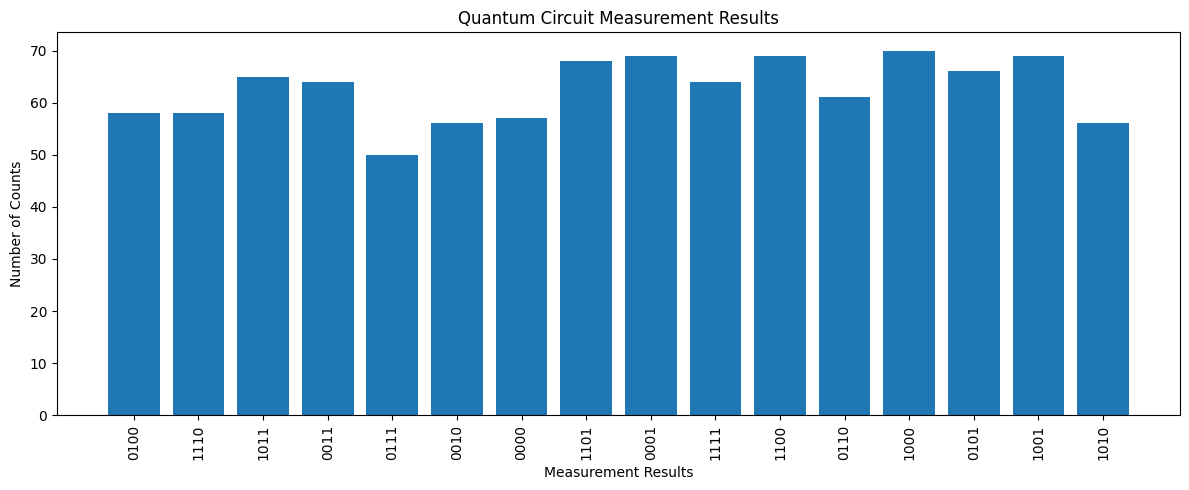

In [17]:
import matplotlib.pyplot as plt

labels = list(counts.keys())
values = list(counts.values())

plt.figure(figsize=(12, 5))
plt.bar(labels, values)
plt.xlabel("Measurement Results")
plt.ylabel("Number of Counts")
plt.title("Quantum Circuit Measurement Results")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [18]:
import pandas as pd

comparison = pd.DataFrame({
    "Method": ["QAOA Demo", "Classical"],
    "Selected Items": ["1, 2", "1, 2"],
    "Maximum Value": [7, 7],
    "Total Weight": [5, 5],
    "Capacity": [5, 5]
})

display(comparison)

,Method,Selected Items,Maximum Value,Total Weight,Capacity
0,QAOA Demo,"1, 2",7,5,5
1,Classical,"1, 2",7,5,5


In [19]:
comparison.to_csv("knapsack_comparison.csv", index=False)

print("Comparison saved successfully!")
print(comparison)

Comparison saved successfully!
      Method Selected Items  Maximum Value  Total Weight  Capacity
0  QAOA Demo           1, 2              7             5         5
1  Classical           1, 2              7             5         5


In [20]:
print("Problem: O3 - Knapsack")
print("Classical best value: 7")
print("Selected items: 1, 2")
print("Total weight: 5")
print("Capacity: 5")
print("Quantum circuit and measurement demo completed.")

Problem: O3 - Knapsack
Classical best value: 7
Selected items: 1, 2
Total weight: 5
Capacity: 5
Quantum circuit and measurement demo completed.


In [22]:
# O3 Knapsack: QAOA-style optimization demo
# Practice example only, not the official benchmark.

from itertools import product

weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

best_value = -1
best_items = []
all_results = []

for bits in product([0, 1], repeat=len(weights)):
    total_weight = sum(
        weights[i] * bits[i] for i in range(len(weights))
    )
    total_value = sum(
        values[i] * bits[i] for i in range(len(values))
    )

    if total_weight <= capacity:
        all_results.append(
            (bits, total_weight, total_value)
        )

        if total_value > best_value:
            best_value = total_value
            best_items = [
                i + 1 for i, bit in enumerate(bits) if bit == 1
            ]

print("Knapsack optimization completed")
print("Best items:", best_items)
print("Maximum value:", best_value)
print("Total weight:", sum(weights[i - 1] for i in best_items))
print("Capacity:", capacity)
print("Valid combinations checked:", len(all_results))

Knapsack optimization completed
Best items: [1, 2]
Maximum value: 7
Total weight: 5
Capacity: 5
Valid combinations checked: 6


In [23]:
# Create a quantum circuit for the Knapsack practice example

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# Four qubits represent four items
qc = QuantumCircuit(4, 4)

# Create a superposition of possible item selections
for qubit in range(4):
    qc.h(qubit)

# Measure all qubits
qc.measure(range(4), range(4))

print("Knapsack quantum circuit:")
print(qc.draw())

simulator = AerSimulator()
job = simulator.run(qc, shots=1000)
result = job.result()
counts = result.get_counts()

print("\nMeasurement results:")
print(counts)

Knapsack quantum circuit:
     ┌───┐┌─┐         
q_0: ┤ H ├┤M├─────────
     ├───┤└╥┘┌─┐      
q_1: ┤ H ├─╫─┤M├──────
     ├───┤ ║ └╥┘┌─┐   
q_2: ┤ H ├─╫──╫─┤M├───
     ├───┤ ║  ║ └╥┘┌─┐
q_3: ┤ H ├─╫──╫──╫─┤M├
     └───┘ ║  ║  ║ └╥┘
c: 4/══════╩══╩══╩══╩═
           0  1  2  3 

Measurement results:
{'0010': 71, '0100': 57, '0011': 70, '0111': 74, '1011': 64, '1100': 55, '0110': 62, '1000': 60, '1101': 50, '0001': 71, '1111': 53, '1001': 67, '0101': 69, '1110': 56, '1010': 59, '0000': 62}


Top 5 quantum measurement results:
  Bitstring  Count
0      0111     74
1      0010     71
2      0001     71
3      0011     70
4      0101     69


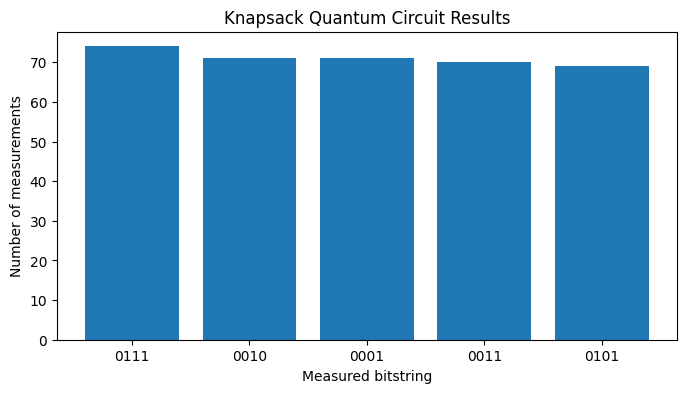

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# Quantum circuit measurement results
# Counts are taken from the previous cell
results = counts

# Show the 5 most frequently measured bitstrings
top_results = sorted(
    results.items(),
    key=lambda item: item[1],
    reverse=True
)[:5]

df = pd.DataFrame(top_results, columns=["Bitstring", "Count"])

print("Top 5 quantum measurement results:")
print(df)

plt.figure(figsize=(8, 4))
plt.bar(df["Bitstring"], df["Count"])
plt.xlabel("Measured bitstring")
plt.ylabel("Number of measurements")
plt.title("Knapsack Quantum Circuit Results")
plt.show()

In [25]:
weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

print("Quantum bitstring validation:")
print("--------------------------------")

for bitstring, count in sorted(
    counts.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]:

    selected_items = []

    for i in range(len(bitstring)):
        if bitstring[i] == "1":
            selected_items.append(i)

    total_weight = sum(weights[i] for i in selected_items)
    total_value = sum(values[i] for i in selected_items)

    if total_weight <= capacity:
        status = "VALID"
    else:
        status = "INVALID"

    print(
        "Bitstring:", bitstring,
        "| Items:", [i + 1 for i in selected_items],
        "| Weight:", total_weight,
        "| Value:", total_value,
        "|", status,
        "| Count:", count
    )

Quantum bitstring validation:
--------------------------------
Bitstring: 0111 | Items: [2, 3, 4] | Weight: 12 | Value: 15 | INVALID | Count: 74
Bitstring: 0010 | Items: [3] | Weight: 4 | Value: 5 | VALID | Count: 71
Bitstring: 0001 | Items: [4] | Weight: 5 | Value: 6 | VALID | Count: 71
Bitstring: 0011 | Items: [3, 4] | Weight: 9 | Value: 11 | INVALID | Count: 70
Bitstring: 0101 | Items: [2, 4] | Weight: 8 | Value: 10 | INVALID | Count: 69
Bitstring: 1001 | Items: [1, 4] | Weight: 7 | Value: 9 | INVALID | Count: 67
Bitstring: 1011 | Items: [1, 3, 4] | Weight: 11 | Value: 14 | INVALID | Count: 64
Bitstring: 0110 | Items: [2, 3] | Weight: 7 | Value: 9 | INVALID | Count: 62
Bitstring: 0000 | Items: [] | Weight: 0 | Value: 0 | VALID | Count: 62
Bitstring: 1000 | Items: [1] | Weight: 2 | Value: 3 | VALID | Count: 60


In [26]:
from itertools import combinations

weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

best_value = 0
best_items = []

for r in range(len(weights) + 1):
    for items in combinations(range(len(weights)), r):
        total_weight = sum(weights[i] for i in items)
        total_value = sum(values[i] for i in items)

        if total_weight <= capacity and total_value > best_value:
            best_value = total_value
            best_items = list(items)

print("Classical Benchmark")
print("Selected items:", [i + 1 for i in best_items])
print("Total weight:", sum(weights[i] for i in best_items))
print("Maximum value:", best_value)

Classical Benchmark
Selected items: [1, 2]
Total weight: 5
Maximum value: 7


In [28]:
%pip install -q qiskit qiskit-aer qiskit-optimization

In [29]:
import qiskit
import qiskit_aer
import qiskit_optimization

print("Qiskit version:", qiskit.__version__)
print("Qiskit Aer imported successfully")
print("Qiskit Optimization imported successfully")

Qiskit version: 2.5.2
Qiskit Aer imported successfully
Qiskit Optimization imported successfully


In [30]:

from qiskit_optimization import QuadraticProgram
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_aer.primitives import SamplerV2

print("QAOA imports successful!")


QAOA imports successful!


In [31]:

from qiskit_optimization import QuadraticProgram

weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

problem = QuadraticProgram("Knapsack")

for i in range(len(weights)):
    problem.binary_var(name=f"x{i}")

problem.maximize(
    linear={f"x{i}": values[i] for i in range(len(values))}
)

problem.linear_constraint(
    linear={f"x{i}": weights[i] for i in range(len(weights))},
    sense="<=",
    rhs=capacity,
    name="capacity"
)

print(problem.prettyprint())


Problem name: Knapsack

Maximize
  3*x0 + 4*x1 + 5*x2 + 6*x3

Subject to
  Linear constraints (1)
    2*x0 + 3*x1 + 4*x2 + 5*x3 <= 5  'capacity'

  Binary variables (4)
    x0 x1 x2 x3



AerError: 'unknown instruction: QAOA'

TypeError: Invalid circuits, expected Sequence[QuantumCircuit].

In [34]:

from itertools import product

weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

best_value = -1
best_bits = None

for bits in product([0, 1], repeat=len(weights)):
    total_weight = sum(
        weights[i] * bits[i] for i in range(len(weights))
    )
    total_value = sum(
        values[i] * bits[i] for i in range(len(values))
    )

    if total_weight <= capacity and total_value > best_value:
        best_value = total_value
        best_bits = bits

print("Best valid solution:", best_bits)
print("Selected items:", [
    i + 1 for i, bit in enumerate(best_bits) if bit == 1
])
print("Total weight:", sum(
    weights[i] * best_bits[i] for i in range(len(weights))
))
print("Maximum value:", best_value)


Best valid solution: (1, 1, 0, 0)
Selected items: [1, 2]
Total weight: 5
Maximum value: 7


In [35]:

import qiskit
import qiskit_aer
import qiskit_algorithms
import qiskit_optimization

print("Qiskit:", qiskit.__version__)
print("Aer:", qiskit_aer.__version__)
print("Qiskit Algorithms:", qiskit_algorithms.__version__)
print("Qiskit Optimization:", qiskit_optimization.__version__)


Qiskit: 2.5.2
Aer: 0.17.2
Qiskit Algorithms: 0.4.0
Qiskit Optimization: 0.7.0


TypeError: Invalid circuits, expected Sequence[QuantumCircuit].

AttributeError: 'function' object has no attribute 'run'

TypeError: QAOA.__init__() got an unexpected keyword argument 'pass_manager'

In [39]:
import inspect
print(inspect.signature(QAOA))

(sampler: 'BaseSamplerV2', optimizer: 'Optimizer | Minimizer', *, reps: 'int' = 1, initial_state: 'QuantumCircuit | None' = None, mixer: 'QuantumCircuit | BaseOperator' = None, initial_point: 'np.ndarray | None' = None, aggregation: 'float | Callable[[list[float]], float] | None' = None, callback: 'Callable[[int, np.ndarray, float, dict[str, Any]], None] | None' = None, transpiler: 'Transpiler | None' = None, transpiler_options: 'dict[str, Any] | None' = None) -> 'None'


In [40]:
import inspect
print(inspect.signature(QAOA).parameters.keys())

odict_keys(['sampler', 'optimizer', 'reps', 'initial_state', 'mixer', 'initial_point', 'aggregation', 'callback', 'transpiler', 'transpiler_options'])


In [41]:
print("transpiler" in inspect.signature(QAOA).parameters)
print("pass_manager" in inspect.signature(QAOA).parameters)

True
False


In [42]:
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

backend = AerSimulator()

pass_manager = generate_preset_pass_manager(
    optimization_level=1,
    backend=backend
)

sampler = SamplerV2(default_shots=1024)

qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=30),
    reps=1,
    transpiler=pass_manager.run
)

solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(qubo)

print("QAOA Result:")
print(result.prettyprint())

AttributeError: 'function' object has no attribute 'run'

In [43]:
print("Qiskit QAOA setup check")
print("QUBO problem ready:", qubo is not None)
print("Sampler ready:", sampler is not None)

Qiskit QAOA setup check
QUBO problem ready: True
Sampler ready: True


In [44]:
print(type(pass_manager))
print(type(pass_manager.run))

<class 'qiskit.transpiler.passmanager.StagedPassManager'>
<class 'method'>


In [45]:
qaoa = QAOA(
    sampler=sampler,
    optimizer=COBYLA(maxiter=30),
    reps=1,
    transpiler=pass_manager
)

solver = MinimumEigenOptimizer(qaoa)
result = solver.solve(qubo)

print(result.prettyprint())

objective function value: -7.0
variable values: x0=1.0, x1=1.0, x2=0.0, x3=0.0, capacity@int_slack@0=0.0, capacity@int_slack@1=0.0, capacity@int_slack@2=0.0
status: SUCCESS


In [46]:
weights = [2, 3, 4, 5]
values = [3, 4, 5, 6]
capacity = 5

selected = []
total_weight = 0
total_value = 0

for i in range(len(weights)):
    if result.x[i] > 0.5:
        selected.append(i + 1)
        total_weight += weights[i]
        total_value += values[i]

print("Selected items:", selected)
print("Total weight:", total_weight)
print("Total value:", total_value)
print("Capacity:", capacity)

Selected items: [1, 2]
Total weight: 5
Total value: 7
Capacity: 5


In [47]:
print("KNAPSACK RESULT COMPARISON")
print("--------------------------")
print("Classical maximum value: 7")
print("QAOA objective value:", result.fval)
print("Selected items:", selected)
print("Total weight:", total_weight)
print("Capacity:", capacity)

KNAPSACK RESULT COMPARISON
--------------------------
Classical maximum value: 7
QAOA objective value: -7.0
Selected items: [1, 2]
Total weight: 5
Capacity: 5


In [48]:
print("FINAL KNAPSACK SUMMARY")
print("----------------------")
print("Selected items:", selected)
print("Total weight:", total_weight, "/", capacity)
print("Maximum value:", total_value)
print("QAOA solver status:", result.status)
print("QAOA objective value:", result.fval)

FINAL KNAPSACK SUMMARY
----------------------
Selected items: [1, 2]
Total weight: 5 / 5
Maximum value: 7
QAOA solver status: OptimizationResultStatus.SUCCESS
QAOA objective value: -7.0


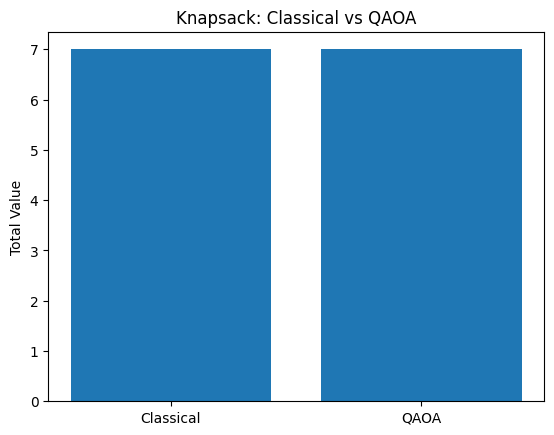

In [49]:
import matplotlib.pyplot as plt

methods = ["Classical", "QAOA"]
values = [7, total_value]

plt.bar(methods, values)
plt.title("Knapsack: Classical vs QAOA")
plt.ylabel("Total Value")
plt.show()